# Three drift corrections tested: MDC, TrDC and ICDC

Fifth notebook of `nov2026_outlook/`. The La Niña outlook of the 1 Nov 2026 start depends more on the drift
correction than on anything else (`01`, `03`). This notebook compares the three standard corrections in one
framework, on every Reanalysis start month (Feb, May, Aug, Nov; the cache of `04`):

| method | drift at start year $j$, lead $\tau$ | addresses |
|---|---|---|
| **MDC**, mean drift (ICPO 2011; Boer et al. 2016) | $d(\tau) = \overline{d_j(\tau)}$ | what is used now |
| **TrDC**, trend-based (Kharin et al. 2012) | $d(j,\tau) = d_{MDC}(\tau) + (\beta_{model}(\tau) - \beta_{obs}(\tau))(j - \bar j)$ | the base-period sensitivity: a drift that changes over the start years |
| **ICDC**, initial-condition-based (Fučkar et al. 2014) | $d(j,\tau) = d_{MDC}(\tau) + \gamma(\tau)(\eta_j - \bar\eta)$ | a drift that depends on the initial state; 2026 starts from a strong El Niño |
| **TrDC + ICDC** | both terms, fitted together | both |

$d_j(\tau)$ is the ensemble mean minus HadISST at the verification month, $\beta$ the linear trends of the
model and the observations over the start years (their difference is the slope of $d_j$ on $j$, so TrDC is
the per-lead least-squares line of the drift on the start year), and $\eta_j$ the observed index anomaly
just before the start. All methods are fitted per start month and lead; the corrected forecast is
model − $d$, and forecast and observed anomalies are both taken from the observed 1991-2020 climatology
(one fixed reference, so the scores and La Niña events are comparable across methods; `03`'s T2 used a moving
reference). In `03`'s terms TrDC is T1; T2 is the same corrected value against a moving reference.

**Tests.**
1. Diagnostics: $\beta_{model} - \beta_{obs}$ and $\gamma$ by lead, and the 2026 $\eta$ against the training range.
2. **Test in time**: trained on the 1981-2008 starts, verified on 2009-2018 (extrapolation, as for 2026).
3. **Cross-validation**: each 1981-2018 start corrected from the other starts (those within 2 years left out),
   scored on all starts and on the starts from an El Niño state, the case of 2026.
4. The 1 Nov 2026 outlook under each method.

**Caution on ICDC.** $\eta$ and the forecast's own ENSO error are linked: ICDC corrects any systematic
state-dependent error (e.g. E3SM's late decay after strong El Niños, `02`), not only drift. Its $\gamma$ rests
on a few strong-event starts, and 2026 is at or beyond the training range of $\eta$.

In [1]:
%matplotlib inline
import sys
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf

### Run controls

In [2]:
NOTEBOOK = "nov2026_outlook/05_drift_correction_methods"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/05_drift_correction_methods/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"

YEAR, INIT = 2026, 11
NLEAD_REF = rc.NLEAD
NLEAD = rc.start_nlead(YEAR, INIT)
INITS = (2, 5, 8, 11)
INIT_NAME = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}
REF_YEARS = (1981, 2018)
OBS_BASE = (1991, 2020)                     # observed climatology: anomaly reference of every method
TRAIN, VERIFY = (1981, 2008), (2009, 2018)  # test in time (as 03, 04)
CV_GAP = 2                                  # cross-validation: starts within this many years of the verified one are left out
# eta: observed anomaly averaged over these months relative to the start (Aug-Sep for a Nov start). Ending two
# months before the start keeps the 2026 value inside the observations (HadISST ends Sep 2026).
ETA_LAGS = (-3, -2)
EL_NINO_ETA = 1.0                           # "El Nino state" starts for the conditional scores (deg C)
METHODS = {                                 # (trend term, initial-condition term)
    "MDC": (False, False),
    "TrDC": (True, False),
    "ICDC": (False, True),
    "TrDC + ICDC": (True, True),
}
COLORS = {"MDC": "tab:red", "TrDC": "tab:blue", "ICDC": "tab:green", "TrDC + ICDC": "tab:purple"}
TREND_YEARS_2026 = {"at 2018": 2018, "at 2026": None}   # where TrDC is evaluated for 2026 (2018: last start, no extrapolation)
ADJUST_LEADS = 3
POOL = {name: rc.CASES[name]["case_prefix"] for name in rc.POOLED_CASES}
NINO_BOX = rc.NINO_REGIONS["Nino3.4"]
TROPICAL_BOX = (0.0, 360.0, -20.0, 20.0)
OBS_PRODUCT = "HadISST1.1"
THRESHOLD = -0.5
WINTERS = {"2026/27": 1, "2027/28": 13, "2028/29": 25}
SEASON_CENTRES = {"year 1": range(1, 12), "year 2": range(12, 23)}
N_BOOT = 2000

# year-3 factor r of the adjusted rule: tested in 04 (r = r6^2), else 1
R04 = rc.output_dir("nov2026_outlook/04_start_months_and_year3_test", "data") / "year3_rule_fitted_r.csv"
R_TESTED = (float(pd.read_csv(R04).query("index == 'Nino3.4' and `drift base` == '1981-2010'")["implied 12-month r = r6^2"].iloc[0])
            if R04.is_file() else 1.0)
R_VALUES = {"r = 0": 0.0, f"r = {R_TESTED:.2f} (04)": R_TESTED, "r = 1": 1.0}
R_PLOT = 1.0                                # year-3 factor of the figure: r = 1 keeps the MDC drift continuous at lead 24 (01)

DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))

### Load: member-level indices of every start month (the cache of `04`; built here if missing)

In [3]:
%%time
CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                    f"nino34_trop_members_init{''.join(f'{m:02d}' for m in INITS)}_ref{REF_YEARS[0]}-{REF_YEARS[1]}"
                    f"_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
NOV_CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                        f"nino34_trop_members_init{INIT:02d}_ref{REF_YEARS[0]}-{REF_YEARS[1]}_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
NOV_EXPECTED = {"ref_years": f"{REF_YEARS[0]}-{REF_YEARS[1]}", "year": YEAR, "init": INIT, "nlead": NLEAD,
                "pool": ",".join(POOL), "obs": OBS_PRODUCT}
EXPECTED = {**NOV_EXPECTED, "inits": ",".join(map(str, INITS))}
YEARS = np.arange(REF_YEARS[0], REF_YEARS[1] + 1)


def valid(path, expected):
    return path.is_file() and all(str(load_netcdf(path).attrs.get(k)) == str(v) for k, v in expected.items())


def build():
    ocean = rc.land_fraction() < 0.5
    idx = lambda da: (rc.box_mean(da, NINO_BOX).load(), rc.box_mean(da.where(ocean), TROPICAL_BOX).load())
    rn = np.full((len(INITS), YEARS.size, rc.NENS, NLEAD_REF), np.nan)
    rt = rn.copy()
    nov = load_netcdf(NOV_CACHE) if derivation_mode != "rebuild" and valid(NOV_CACHE, NOV_EXPECTED) else None
    for i, init in enumerate(INITS):
        if init == INIT and nov is not None:
            rn[i], rt[i] = nov["ref_nino"].sel(year=YEARS).values, nov["ref_trop"].sel(year=YEARS).values
            continue
        for k, y in enumerate(YEARS):
            if rc.member_file(rc.REFERENCE["case_prefix"], int(y), init, 0, "TS") is None:
                continue
            ens = rc.open_hindcast(rc.REFERENCE["case_prefix"], int(y), init, "TS")
            if ens is None:
                continue
            n, t = idx(ens)
            rn[i, k, ens["member"].values], rt[i, k, ens["member"].values] = n.values, t.values
    if nov is not None:
        fc = {v: nov[v].values for v in ("fc_nino", "fc_trop", "obs_nino", "obs_trop")}
        members, times = nov["member"].values, nov["time"].values
    else:
        fn, ft, members = [], [], []
        for name, prefix in POOL.items():
            ens = rc.open_hindcast(prefix, YEAR, INIT, "TS")
            n, t = idx(ens)
            fn.append(n.values), ft.append(t.values)
            members += [f"{rc.CASES[name]['short']}:{m}" for m in ens["member"].values]
        obs = rc.obs_monthly("TS", years=(REF_YEARS[0], YEAR), mode=derivation_mode, product=OBS_PRODUCT)
        on, ot = idx(obs)
        fc = {"fc_nino": np.concatenate(fn), "fc_trop": np.concatenate(ft), "obs_nino": on.values, "obs_trop": ot.values}
        times = [f"{t.year:04d}-{t.month:02d}" for t in obs["time"].to_index()]
    ds = xr.Dataset(
        {"ref_nino": (("init", "year", "ens", "lead"), rn), "ref_trop": (("init", "year", "ens", "lead"), rt),
         "fc_nino": (("member", "flead"), fc["fc_nino"]), "fc_trop": (("member", "flead"), fc["fc_trop"]),
         "obs_nino": ("time", fc["obs_nino"]), "obs_trop": ("time", fc["obs_trop"])},
        coords={"init": list(INITS), "year": YEARS, "ens": np.arange(rc.NENS), "lead": np.arange(NLEAD_REF),
                "member": members, "flead": np.arange(NLEAD), "time": times})
    ds.attrs.update(EXPECTED, units="degC")
    return ds


if derivation_mode != "rebuild" and valid(CACHE, EXPECTED):
    D = load_netcdf(CACHE)
else:
    D = build()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    atomic_to_netcdf(D, CACHE)
AVAIL = {init: YEARS[np.isfinite(D["ref_nino"].sel(init=init).values).any(axis=(1, 2))] for init in INITS}
for init in INITS:
    print(f"{INIT_NAME[init]}: {AVAIL[init].size} starts ({AVAIL[init][0]}-{AVAIL[init][-1]})")
print(f"{D.sizes['member']} forecast members; HadISST {str(D.time.values[0])} to {str(D.time.values[-1])}")

Feb: 7 starts (1985-2015)
May: 38 starts (1981-2018)
Aug: 7 starts (1985-2015)
Nov: 38 starts (1981-2018)
30 forecast members; HadISST 1981-01 to 2026-09
CPU times: user 739 ms, sys: 274 ms, total: 1.01 s
Wall time: 1.03 s


### Helpers

`fit_drift` regresses the per-start drift on the method's predictors (intercept; $j - \bar j$; $\eta_j - \bar\eta$)
at every lead, over the training starts of one start month; `correction` evaluates it for a start
(year, $\eta$) and adds the observed 1991-2020 climatology. Leads 24-35 of the 2026 start: the MDC part (the
intercept) follows the adjusted year-3 rule of `01` with factor $r$, which works by target month; the trend
and initial-state terms are functions of lead, not of target month, and hold their lead-23 value. (Copying
them by target month, as the rule does for the MDC part, puts the lead-12 term next to the lead-23 one at the
year-2-to-3 boundary: with $\gamma$ going from −0.1 to +0.56 over year 2 and $\eta$ = 2.5, a jump of about
+1.7 °C in Nov 2028.)

In [4]:
OBS = pd.Series(D["obs_nino"].values, index=pd.PeriodIndex(D["time"].values, freq="M"))
OBS_T = pd.Series(D["obs_trop"].values, index=OBS.index)


def target(y, init, lead):
    return pd.Period(year=int(y), month=int(init), freq="M") + int(lead)


def data(kind):
    if kind == "Nino3.4":
        return D["ref_nino"].values, D["fc_nino"].values, OBS
    return (D["ref_nino"] - D["ref_trop"]).values, (D["fc_nino"] - D["fc_trop"]).values, OBS - OBS_T


def obs_clim(obs, base):
    sel = obs[(obs.index.year >= base[0]) & (obs.index.year <= base[1])]
    return sel.groupby(sel.index.month).mean()


@lru_cache(maxsize=None)
def obs_anom(kind):
    obs = data(kind)[2]
    return obs - obs_clim(obs, OBS_BASE).reindex(obs.index.month).values


def obs_at(obs, init, years, leads=range(NLEAD_REF)):
    return np.array([[obs.get(target(y, init, L), np.nan) for L in leads] for y in years])


def eta(kind, init, year):
    a = obs_anom(kind)
    return float(np.mean([a[target(year, init, L)] for L in ETA_LAGS]))


@lru_cache(maxsize=None)
def drift_table(kind, init):
    # all starts of a start month: years, eta (year,), drift (year, lead), members (year, ens, lead)
    ref, _, obs = data(kind)
    years = AVAIL[init]
    members = ref[INITS.index(init)][np.searchsorted(YEARS, years)]
    dd = np.nanmean(members, axis=1) - obs_at(obs, init, years)
    return years, np.array([eta(kind, init, y) for y in years]), dd, members


def fit_drift(kind, init, train_years, method):
    # least squares at every lead: coefficients (p, lead), centring (mean year, mean eta)
    years, et, dd, _ = drift_table(kind, init)
    sel = np.isin(years, train_years)
    y, e, d = years[sel].astype(float), et[sel], dd[sel]
    trend, ic = METHODS[method]
    cols = [np.ones(y.size)] + ([y - y.mean()] if trend else []) + ([e - e.mean()] if ic else [])
    coef = np.linalg.lstsq(np.column_stack(cols), d, rcond=None)[0]
    return coef, y.mean(), e.mean()


def extend(c, nlead, r=1.0):
    if nlead <= NLEAD_REF:
        return c[:nlead]
    delta = c[12:24] - c[:12]
    delta = np.where(np.arange(12) < ADJUST_LEADS, delta[ADJUST_LEADS:].mean(), delta)
    return np.r_[c[:NLEAD_REF], c[12:24] + r * delta][:nlead]


def drift_at(fit, method, year, eta_value, nlead=NLEAD_REF, r=1.0):
    # MDC part (the intercept: predictors are centred) + trend and initial-state terms. Leads >= 24: the MDC
    # part follows the year-3 rule (by target month); the other terms depend on lead, not target month, so
    # they hold their lead-23 value (copying them by target month makes the lead-24 step)
    coef, ybar, ebar = fit
    trend, ic = METHODS[method]
    x = np.array(([year - ybar] if trend else []) + ([eta_value - ebar] if ic else []))
    terms = x @ coef[1:] if x.size else np.zeros(NLEAD_REF)
    return extend(coef[0], nlead, r) + np.r_[terms, np.full(max(nlead - NLEAD_REF, 0), terms[-1])][:nlead]


def correction(kind, init, method, train_years, year, eta_value, nlead=NLEAD_REF, trend_year=None, r=1.0):
    # subtract from the model to get its anomaly (drift + observed 1991-2020 climatology of the target month)
    d = drift_at(fit_drift(kind, init, train_years, method), method, year if trend_year is None else trend_year,
                 eta_value, nlead, r)
    months = [target(year, init, L).month for L in range(nlead)]
    return d + obs_clim(data(kind)[2], OBS_BASE).loc[months].values


def run3(a):
    out = np.full(a.shape, np.nan)
    out[..., 1:-1] = (a[..., :-2] + a[..., 1:-1] + a[..., 2:]) / 3.0
    return out


def djf(a, first):
    return a[..., first:first + 3].mean(-1)


def season_scores(fc, ob):
    # fc (ens, lead) and ob (lead) anomalies -> {lead year: (ensemble-mean error, La Nina prob, observed event)}
    f3, o3 = run3(fc), run3(ob)
    out = {}
    for lab, cen in SEASON_CENTRES.items():
        c = list(cen)
        out[lab] = (np.nanmean(f3[:, c], 0) - o3[c], np.nanmean(f3[:, c] <= THRESHOLD, 0), (o3[c] <= THRESHOLD).astype(float))
    return out


ETA_2026 = {k: eta(k, INIT, YEAR) for k in ("Nino3.4", "Relative")}
for k in ETA_2026:
    _, et, _, _ = drift_table(k, INIT)
    print(f"{k}: eta (Aug-Sep) of the 1 Nov 2026 start {ETA_2026[k]:+.2f} °C; Nov starts 1981-2018: "
          f"{et.min():+.2f} to {et.max():+.2f} (largest: {', '.join(str(y) for y in AVAIL[INIT][np.argsort(et)[-3:][::-1]])})")

Nino3.4: eta (Aug-Sep) of the 1 Nov 2026 start +2.50 °C; Nov starts 1981-2018: -1.47 to +2.01 (largest: 1997, 2015, 1987)
Relative: eta (Aug-Sep) of the 1 Nov 2026 start +1.75 °C; Nov starts 1981-2018: -1.30 to +1.77 (largest: 1997, 2015, 1982)


### 1. Diagnostics: the trend and initial-state terms

Top: Niño3.4 drift of the Nov starts in the DJF of year 2 against the start year (colour: $\eta$) and against
$\eta$ (colour: start year), with the TrDC and ICDC lines; dotted: 2026. Bottom, by lead (Nov and May starts,
all 1981-2018): $\beta_{model}$, $\beta_{obs}$ and their difference (the TrDC slope), and $\gamma$ (ICDC);
shading: 90% bootstrap over start years.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/05_drift_correction_methods/figures/fig_methods_trend_and_initial_state_terms.png


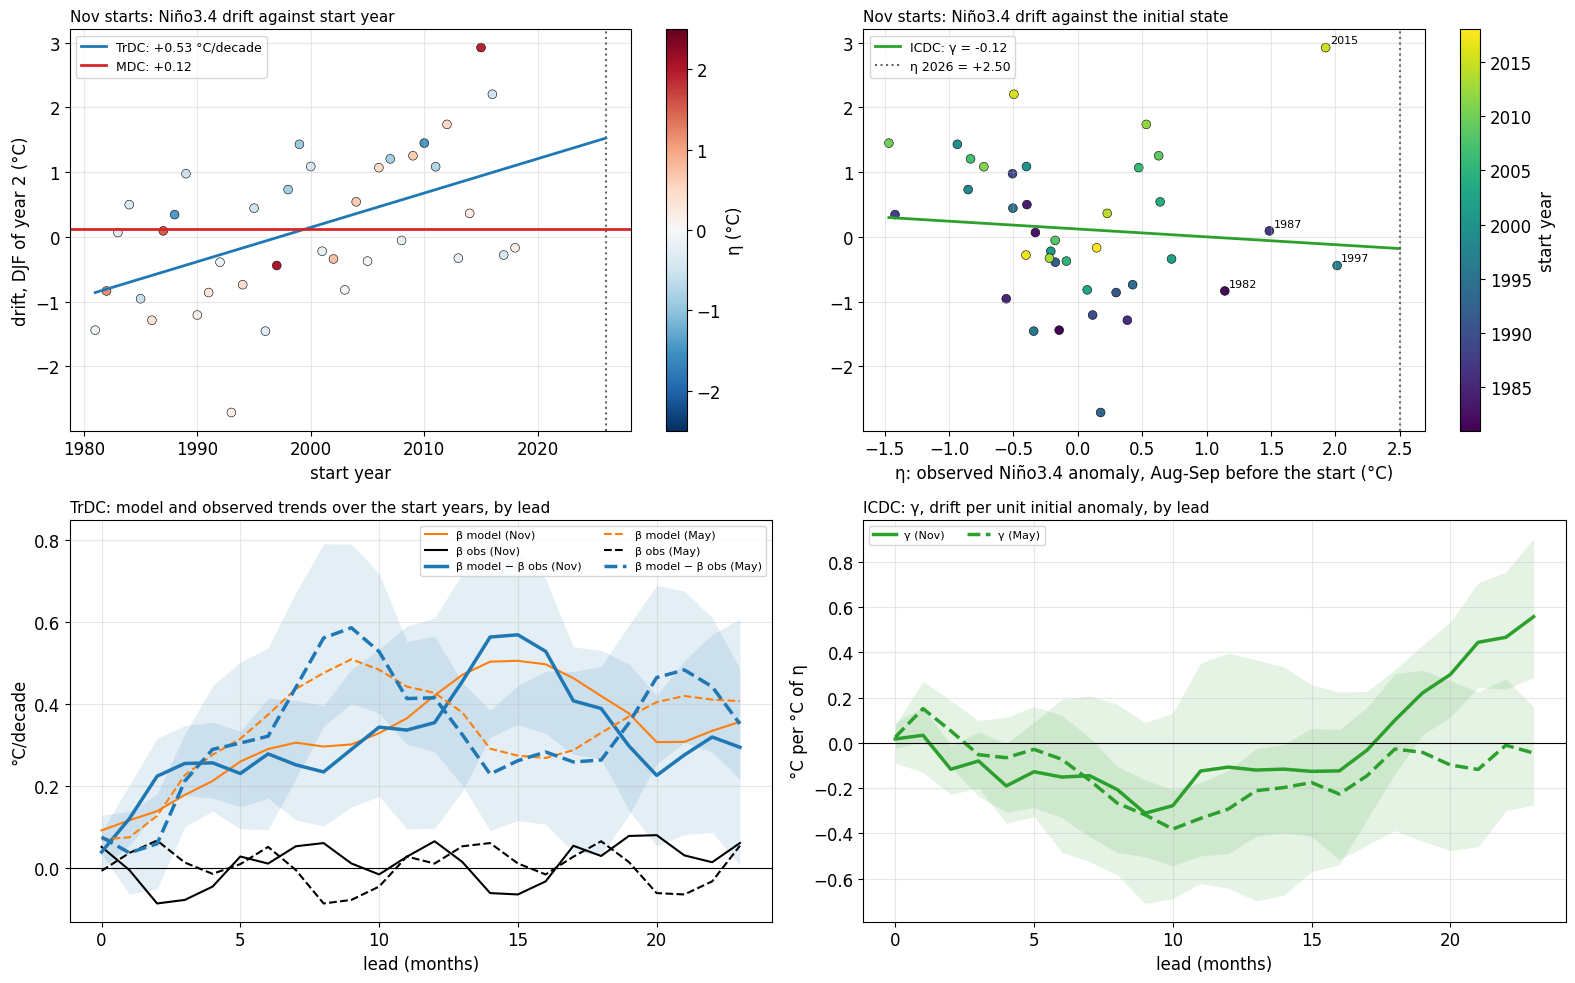

,start month,leads,β model (°C/decade),β obs (°C/decade),β model − β obs,γ (°C per °C of η),γ × η 2026 − η mean (°C)
0,Nov,year 1 (leads 3-11),0.28,0.01,0.28,-0.18,-0.45
1,Nov,year 2 (leads 12-23),0.41,0.02,0.39,0.12,0.30
2,May,year 1 (leads 3-11),0.39,-0.01,0.41,-0.19,-0.47
3,May,year 2 (leads 12-23),0.36,0.01,0.35,-0.13,-0.33


In [5]:
def beta(years, x):
    yd = years - years.mean()
    return (yd @ (x - x.mean(0))) / (yd @ yd)


rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
years, et, dd, members = drift_table("Nino3.4", INIT)
d2 = djf(dd, 13)
ax = axes[0, 0]
sc = ax.scatter(years, d2, c=et, cmap="RdBu_r", vmin=-2.5, vmax=2.5, s=40, edgecolor="k", lw=0.4)
b, a = np.polyfit(years, d2, 1)
ax.plot([years[0], YEAR], [a + b * years[0], a + b * YEAR], color="tab:blue", lw=2, label=f"TrDC: {10 * b:+.2f} °C/decade")
ax.axhline(d2.mean(), color="tab:red", lw=2, label=f"MDC: {d2.mean():+.2f}")
ax.axvline(YEAR, color="0.4", ls=":")
plt.colorbar(sc, ax=ax, label="η (°C)")
ax.set_xlabel("start year")
ax.set_ylabel("drift, DJF of year 2 (°C)")
ax.set_title("Nov starts: Niño3.4 drift against start year", loc="left", fontsize=11)
ax.legend(fontsize=9)
ax = axes[0, 1]
sc = ax.scatter(et, d2, c=years, cmap="viridis", s=40, edgecolor="k", lw=0.4)
g, a = np.polyfit(et, d2, 1)
xx = np.array([min(et.min(), ETA_2026["Nino3.4"]), max(et.max(), ETA_2026["Nino3.4"])])
ax.plot(xx, a + g * xx, color="tab:green", lw=2, label=f"ICDC: γ = {g:+.2f}")
ax.axvline(ETA_2026["Nino3.4"], color="0.4", ls=":", label=f"η 2026 = {ETA_2026['Nino3.4']:+.2f}")
for y, e, v in zip(years, et, d2):
    if e > EL_NINO_ETA:
        ax.annotate(str(y), (e, v), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc, ax=ax, label="start year")
ax.set_xlabel("η: observed Niño3.4 anomaly, Aug-Sep before the start (°C)")
ax.set_title("Nov starts: Niño3.4 drift against the initial state", loc="left", fontsize=11)
ax.legend(fontsize=9)

rows = []
for init, ls in ((11, "-"), (5, "--")):
    years, et, dd, _ = drift_table("Nino3.4", init)
    obs = obs_at(data("Nino3.4")[2], init, years)
    model = dd + obs
    yrs = years.astype(float)
    bm, bo = beta(yrs, model), beta(yrs, obs)
    boot = []
    for _ in range(N_BOOT // 4):
        k = rng.integers(0, yrs.size, yrs.size)
        X = np.column_stack([np.ones(k.size), yrs[k] - yrs[k].mean(), et[k] - et[k].mean()])
        boot.append((beta(yrs[k], dd[k]), np.linalg.lstsq(X[:, [0, 2]], dd[k], rcond=None)[0][1]))
    boot = np.array(boot)
    gam = np.linalg.lstsq(np.column_stack([np.ones(yrs.size), et - et.mean()]), dd, rcond=None)[0][1]
    L = np.arange(NLEAD_REF)
    ax = axes[1, 0]
    ax.plot(L, 10 * bm, color="tab:orange", ls=ls, lw=1.5, label=f"β model ({INIT_NAME[init]})")
    ax.plot(L, 10 * bo, color="k", ls=ls, lw=1.5, label=f"β obs ({INIT_NAME[init]})")
    ax.plot(L, 10 * (bm - bo), color="tab:blue", ls=ls, lw=2.5, label=f"β model − β obs ({INIT_NAME[init]})")
    ax.fill_between(L, *(10 * np.percentile(boot[:, 0], [5, 95], axis=0)), color="tab:blue", alpha=0.12, lw=0)
    ax = axes[1, 1]
    ax.plot(L, gam, color="tab:green", ls=ls, lw=2.5, label=f"γ ({INIT_NAME[init]})")
    ax.fill_between(L, *np.percentile(boot[:, 1], [5, 95], axis=0), color="tab:green", alpha=0.12, lw=0)
    for lab, sl in (("year 1 (leads 3-11)", slice(3, 12)), ("year 2 (leads 12-23)", slice(12, 24))):
        rows.append({"start month": INIT_NAME[init], "leads": lab, "β model (°C/decade)": round(10 * bm[sl].mean(), 2),
                     "β obs (°C/decade)": round(10 * bo[sl].mean(), 2), "β model − β obs": round(10 * (bm - bo)[sl].mean(), 2),
                     "γ (°C per °C of η)": round(gam[sl].mean(), 2),
                     "γ × η 2026 − η mean (°C)": round(gam[sl].mean() * (ETA_2026["Nino3.4"] - et.mean()), 2)})
axes[1, 0].axhline(0, color="k", lw=0.8)
axes[1, 0].set_ylabel("°C/decade")
axes[1, 0].set_title("TrDC: model and observed trends over the start years, by lead", loc="left", fontsize=11)
axes[1, 1].axhline(0, color="k", lw=0.8)
axes[1, 1].set_ylabel("°C per °C of η")
axes[1, 1].set_title("ICDC: γ, drift per unit initial anomaly, by lead", loc="left", fontsize=11)
for ax in axes[1]:
    ax.set_xlabel("lead (months)")
    ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "methods", "trend_and_initial_state_terms")
plt.show()
terms = pd.DataFrame(rows)
terms.to_csv(DATA_DIR / "trdc_icdc_terms.csv", index=False)
display(terms)

### 2. Test in time: trained on 1981-2008, verified on 2009-2018

All start months (10 May, 10 Nov, Feb and Aug 2010 and 2015): every 3-month season of years 1 and 2; mean bias,
RMSE of the ensemble mean and the Brier score of the La Niña probability. TrDC is evaluated at the
verification year, i.e. extrapolated 1-10 years past the training starts. Intervals: 90% bootstrap over
verification years of the difference from MDC.

In [6]:
def scores_for(kind, method, init, year, train_years):
    years, et, dd, members = drift_table(kind, init)
    k = int(np.where(years == year)[0][0])
    sub = correction(kind, init, method, train_years, year, et[k])
    ob = obs_at(data(kind)[2], init, [year])[0] - obs_clim(data(kind)[2], OBS_BASE).loc[[target(year, init, L).month for L in range(NLEAD_REF)]].values
    return season_scores(members[k] - sub[None, :], ob), et[k]


def table(store, keys_of, label):
    rows = []
    for kind in ("Nino3.4", "Relative"):
        for lab in SEASON_CENTRES:
            for subset, cond in (("all starts", lambda e: True), (f"η > {EL_NINO_ETA:g}", lambda e: e > EL_NINO_ETA),
                                 (f"η < −{EL_NINO_ETA:g}", lambda e: e < -EL_NINO_ETA)):
                for method in METHODS:
                    ks = [k for k in keys_of(kind, method) if cond(store[k][1])]
                    if not ks:
                        continue
                    err = np.concatenate([store[k][0][lab][0] for k in ks])
                    bs = np.concatenate([(store[k][0][lab][1] - store[k][0][lab][2]) ** 2 for k in ks])
                    evt = np.concatenate([store[k][0][lab][2] for k in ks])
                    rows.append({"index": kind, "lead year": lab, "starts": f"{subset} ({len(ks)})", "method": method,
                                 "mean bias (°C)": round(err.mean(), 2), "RMSE (°C)": round(np.sqrt(np.mean(err ** 2)), 2),
                                 "Brier (La Niña)": round(bs.mean(), 3), "La Niña seasons": f"{int(evt.sum())}/{evt.size}"})
    out = pd.DataFrame(rows)
    out.to_csv(DATA_DIR / f"{label}.csv", index=False)
    return out


def boot_ci(store, keys_of, years_all, label):
    rng = np.random.default_rng(0)
    boots = [rng.choice(years_all, years_all.size, replace=True) for _ in range(N_BOOT)]
    rows = []
    for kind in ("Nino3.4", "Relative"):
        for lab in SEASON_CENTRES:
            per_year = {}
            for method in METHODS:
                for metric in ("MSE", "Brier"):
                    acc = {}
                    for k in keys_of(kind, method):
                        s = store[k][0][lab]
                        v = s[0] ** 2 if metric == "MSE" else (s[1] - s[2]) ** 2
                        acc.setdefault(k[3], []).append(v)
                    per_year[(method, metric)] = {y: np.concatenate(v) for y, v in acc.items()}
            for method in list(METHODS)[1:]:
                for metric in ("MSE", "Brier"):
                    def score(m, ys):
                        return np.mean(np.concatenate([per_year[(m, metric)][y] for y in ys if y in per_year[(m, metric)]]))
                    diff = np.array([score(method, b) - score("MDC", b) for b in boots])
                    lo, hi = np.percentile(diff, [5, 95])
                    rows.append({"index": kind, "lead year": lab, "method": method, "metric": metric,
                                 "difference from MDC": round(score(method, years_all) - score("MDC", years_all), 3),
                                 "90% interval": f"{lo:+.3f} to {hi:+.3f}", "significant": "yes" if lo > 0 or hi < 0 else ""})
    out = pd.DataFrame(rows)
    out.to_csv(DATA_DIR / f"{label}_ci.csv", index=False)
    return out


TT = {}
for kind in ("Nino3.4", "Relative"):
    for method in METHODS:
        for init in INITS:
            train = AVAIL[init][(AVAIL[init] >= TRAIN[0]) & (AVAIL[init] <= TRAIN[1])]
            for y in AVAIL[init][(AVAIL[init] >= VERIFY[0]) & (AVAIL[init] <= VERIFY[1])]:
                TT[(kind, method, init, int(y))] = scores_for(kind, method, init, int(y), train)
tt_keys = lambda kind, method: [k for k in TT if k[0] == kind and k[1] == method]
test = table(TT, tt_keys, "test_in_time")
with pd.option_context("display.max_rows", 200):
    display(test)
    display(boot_ci(TT, tt_keys, np.arange(VERIFY[0], VERIFY[1] + 1), "test_in_time"))

,index,lead year,starts,method,mean bias (°C),RMSE (°C),Brier (La Niña),La Niña seasons
0,Nino3.4,year 1,all starts (24),MDC,0.52,0.84,0.141,72/264
1,Nino3.4,year 1,all starts (24),TrDC,-0.11,0.77,0.170,72/264
2,Nino3.4,year 1,all starts (24),ICDC,0.55,0.95,0.159,72/264
3,Nino3.4,year 1,all starts (24),TrDC + ICDC,-0.07,0.88,0.179,72/264
4,Nino3.4,year 1,η > 1 (5),MDC,0.69,0.97,0.192,25/55
5,Nino3.4,year 1,η > 1 (5),TrDC,-0.02,1.03,0.237,25/55
6,Nino3.4,year 1,η > 1 (5),ICDC,0.98,1.43,0.294,25/55
7,Nino3.4,year 1,η > 1 (5),TrDC + ICDC,0.29,1.32,0.257,25/55
8,Nino3.4,year 1,η < −1 (2),MDC,0.78,0.91,0.540,17/22
9,Nino3.4,year 1,η < −1 (2),TrDC,0.26,0.54,0.256,17/22


,index,lead year,method,metric,difference from MDC,90% interval,significant
0,Nino3.4,year 1,TrDC,MSE,-0.119,-0.375 to +0.114,
1,Nino3.4,year 1,TrDC,Brier,0.030,-0.038 to +0.106,
2,Nino3.4,year 1,ICDC,MSE,0.187,+0.013 to +0.345,yes
3,Nino3.4,year 1,ICDC,Brier,0.018,-0.001 to +0.041,
4,Nino3.4,year 1,TrDC + ICDC,MSE,0.059,-0.248 to +0.323,
5,Nino3.4,year 1,TrDC + ICDC,Brier,0.038,-0.023 to +0.108,
6,Nino3.4,year 2,TrDC,MSE,-0.730,-0.952 to -0.442,yes
7,Nino3.4,year 2,TrDC,Brier,-0.040,-0.093 to +0.014,
8,Nino3.4,year 2,ICDC,MSE,0.235,-0.030 to +0.525,
9,Nino3.4,year 2,ICDC,Brier,0.009,-0.001 to +0.019,


### 3. Cross-validation over all 1981-2018 starts

Each start is corrected from the starts of the same month more than 2 years away (its own and the neighbouring
starts, whose targets overlap, are left out): 38 May, 38 Nov, 7 Feb and 7 Aug starts. TrDC is evaluated inside
the training period here (interpolation), so this test favours it less than it favours ICDC; section 2 is the
test of extrapolation. Rows "η > 1" are the starts from an El Niño state. Intervals: 90% bootstrap over start
years.

,index,lead year,starts,method,mean bias (°C),RMSE (°C),Brier (La Niña),La Niña seasons
0,Nino3.4,year 1,all starts (90),MDC,0.00,0.71,0.161,318/990
1,Nino3.4,year 1,all starts (90),TrDC,-0.00,0.63,0.158,318/990
2,Nino3.4,year 1,all starts (90),ICDC,0.01,0.73,0.158,318/990
3,Nino3.4,year 1,all starts (90),TrDC + ICDC,-0.00,0.67,0.157,318/990
4,Nino3.4,year 1,η > 1 (13),MDC,-0.14,0.95,0.188,60/143
5,Nino3.4,year 1,η > 1 (13),TrDC,-0.11,0.89,0.198,60/143
6,Nino3.4,year 1,η > 1 (13),ICDC,0.09,1.08,0.198,60/143
7,Nino3.4,year 1,η > 1 (13),TrDC + ICDC,0.06,1.05,0.210,60/143
8,Nino3.4,year 1,η < −1 (9),MDC,0.40,0.61,0.322,73/99
9,Nino3.4,year 1,η < −1 (9),TrDC,0.38,0.56,0.279,73/99


,index,lead year,method,metric,difference from MDC,90% interval,significant
0,Nino3.4,year 1,TrDC,MSE,-0.115,-0.202 to -0.033,yes
1,Nino3.4,year 1,TrDC,Brier,-0.003,-0.025 to +0.021,
2,Nino3.4,year 1,ICDC,MSE,0.027,-0.030 to +0.091,
3,Nino3.4,year 1,ICDC,Brier,-0.002,-0.011 to +0.008,
4,Nino3.4,year 1,TrDC + ICDC,MSE,-0.063,-0.178 to +0.049,
5,Nino3.4,year 1,TrDC + ICDC,Brier,-0.004,-0.028 to +0.023,
6,Nino3.4,year 2,TrDC,MSE,-0.233,-0.376 to -0.085,yes
7,Nino3.4,year 2,TrDC,Brier,-0.005,-0.034 to +0.026,
8,Nino3.4,year 2,ICDC,MSE,0.102,+0.017 to +0.197,yes
9,Nino3.4,year 2,ICDC,Brier,0.001,-0.005 to +0.007,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/05_drift_correction_methods/figures/fig_methods_cv_bias_by_initial_state.png


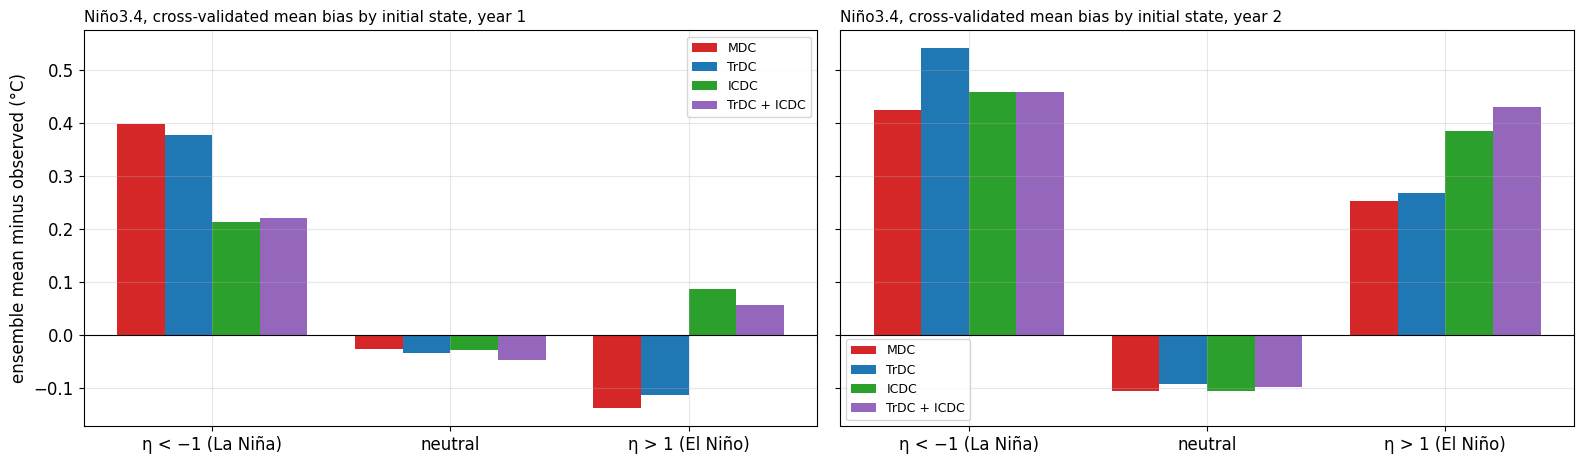

In [7]:
CV = {}
for kind in ("Nino3.4", "Relative"):
    for method in METHODS:
        for init in INITS:
            for y in AVAIL[init]:
                train = AVAIL[init][np.abs(AVAIL[init] - y) > CV_GAP]
                CV[(kind, method, init, int(y))] = scores_for(kind, method, init, int(y), train)
cv_keys = lambda kind, method: [k for k in CV if k[0] == kind and k[1] == method]
cv = table(CV, cv_keys, "cross_validation")
with pd.option_context("display.max_rows", 200):
    display(cv)
    display(boot_ci(CV, cv_keys, YEARS, "cross_validation"))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
bins = [-np.inf, -EL_NINO_ETA, EL_NINO_ETA, np.inf]
blab = [f"η < −{EL_NINO_ETA:g} (La Niña)", "neutral", f"η > {EL_NINO_ETA:g} (El Niño)"]
for ax, lab in zip(axes, SEASON_CENTRES):
    w = 0.2
    for j, method in enumerate(METHODS):
        vals = []
        for lo, hi in zip(bins[:-1], bins[1:]):
            ks = [k for k in cv_keys("Nino3.4", method) if lo < CV[k][1] <= hi]
            vals.append(np.mean(np.concatenate([CV[k][0][lab][0] for k in ks])))
        ax.bar(np.arange(3) + (j - 1.5) * w, vals, w, color=COLORS[method], label=method)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(3), blab)
    ax.set_title(f"Niño3.4, cross-validated mean bias by initial state, {lab}", loc="left", fontsize=11)
    ax.legend(fontsize=9)
axes[0].set_ylabel("ensemble mean minus observed (°C)")
fig.tight_layout()
save(fig, "methods", "cv_bias_by_initial_state")
plt.show()

### 4. The 1 Nov 2026 outlook under each method

Fitted on all 1981-2018 Nov starts, evaluated for the 2026 start ($\eta$ of Aug-Sep 2026; TrDC held at the
last start, 2018, or extrapolated to 2026). Year 3: the MDC part by the adjusted rule with $r$ = 0, the $r$
tested in `04`, and 1; the trend and initial-state terms held at lead 23. The table gives the ensemble-mean
step from Oct to Nov 2028 (lead 23 → 24) for each $r$: a continuous year-2-to-3 transition is the check of
the year-3 drift (`01`). The figure uses $r = 1$. P(La Niña 2027/28) does not depend on $r$.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/05_drift_correction_methods/figures/fig_nov2026_outlook_by_method.png


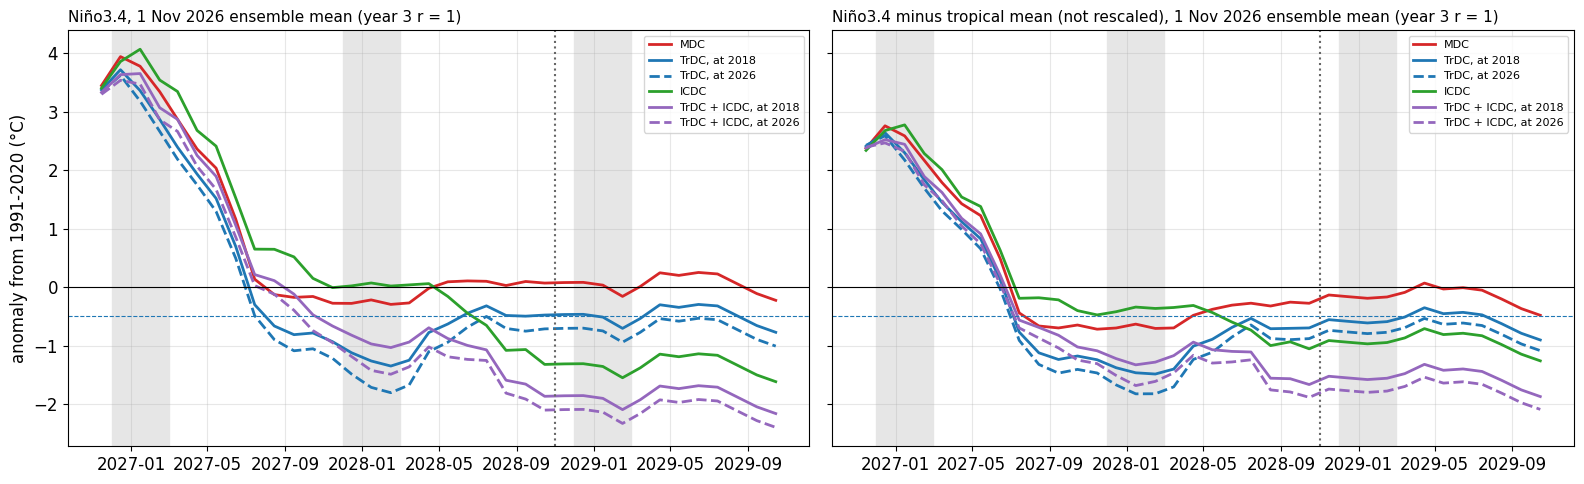

,index,method,DJF 27/28 mean,P(LN 27/28),"P(LN 28/29), r = 0","P(both), r = 0","step Oct→Nov 2028 (°C), r = 0","P(LN 28/29), r = 0.19 (04)","P(both), r = 0.19 (04)","step Oct→Nov 2028 (°C), r = 0.19 (04)","P(LN 28/29), r = 1","P(both), r = 1","step Oct→Nov 2028 (°C), r = 1"
0,Nino3.4,MDC,-0.26,0.40,0.23,0.10,0.33,0.27,0.10,0.27,0.30,0.10,0.01
1,Nino3.4,"TrDC, at 2018",-1.24,0.80,0.37,0.27,0.33,0.40,0.30,0.27,0.50,0.40,0.01
2,Nino3.4,"TrDC, at 2026",-1.67,0.87,0.43,0.40,0.33,0.47,0.43,0.27,0.60,0.57,0.01
3,Nino3.4,ICDC,0.04,0.27,0.63,0.20,0.33,0.63,0.20,0.27,0.77,0.23,0.01
4,Nino3.4,"TrDC + ICDC, at 2018",-0.94,0.70,0.83,0.60,0.33,0.83,0.60,0.27,0.90,0.63,0.01
5,Nino3.4,"TrDC + ICDC, at 2026",-1.37,0.83,0.83,0.70,0.33,0.90,0.77,0.27,0.97,0.83,0.01
6,Relative,MDC,-0.68,0.60,0.30,0.17,0.27,0.30,0.17,0.25,0.33,0.20,0.14
7,Relative,"TrDC, at 2018",-1.44,0.87,0.43,0.40,0.27,0.47,0.43,0.25,0.50,0.47,0.14
8,Relative,"TrDC, at 2026",-1.77,0.97,0.50,0.47,0.27,0.50,0.47,0.25,0.53,0.50,0.14
9,Relative,ICDC,-0.38,0.50,0.53,0.27,0.27,0.53,0.27,0.25,0.63,0.33,0.14


In [8]:
rows = []
x = [target(YEAR, INIT, L).to_timestamp() + pd.Timedelta(days=14) for L in range(NLEAD)]
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, kind in zip(axes, ("Nino3.4", "Relative")):
    _, fc, _ = data(kind)
    for method in METHODS:
        for tlab, ty in (TREND_YEARS_2026.items() if METHODS[method][0] else [("", None)]):
            name = f"{method}, {tlab}" if tlab else method
            row = {"index": kind, "method": name}
            for rlab, r in R_VALUES.items():
                sub = correction(kind, INIT, method, AVAIL[INIT], YEAR, ETA_2026[kind], NLEAD, trend_year=ty, r=r)
                a = fc - sub[None, :]
                v = {w: djf(a, first) for w, first in WINTERS.items()}
                ln = {w: v[w] <= THRESHOLD for w in v}
                if r == 0.0:
                    row["DJF 27/28 mean"] = round(v["2027/28"].mean(), 2)
                    row["P(LN 27/28)"] = round(ln["2027/28"].mean(), 2)
                row[f"P(LN 28/29), {rlab}"] = round(ln["2028/29"].mean(), 2)
                row[f"P(both), {rlab}"] = round((ln["2027/28"] & ln["2028/29"]).mean(), 2)
                row[f"step Oct→Nov 2028 (°C), {rlab}"] = round(float(a.mean(0)[NLEAD_REF] - a.mean(0)[NLEAD_REF - 1]), 2)
                if r == R_PLOT:
                    ax.plot(x, a.mean(0), color=COLORS[method], lw=2, ls="--" if tlab == "at 2026" else "-", label=name)
            rows.append(row)
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
    ax.axvline(x[NLEAD_REF] - pd.Timedelta(days=14), color="0.4", ls=":")
    for first in WINTERS.values():
        ax.axvspan(x[first] - pd.Timedelta(days=14), x[first + 2] + pd.Timedelta(days=14), color="0.9", zorder=0)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean (not rescaled)'}, 1 Nov 2026 ensemble mean (year 3 r = {R_PLOT:g})",
                 loc="left", fontsize=11)
    ax.legend(fontsize=8)
axes[0].set_ylabel("anomaly from 1991-2020 (°C)")
fig.tight_layout()
save(fig, "nov2026", "outlook_by_method")
plt.show()
p2026 = pd.DataFrame(rows)
p2026.to_csv(DATA_DIR / "nov2026_la_nina_by_method.csv", index=False)
with pd.option_context("display.max_columns", 30, "display.width", 250):
    display(p2026)

### Findings

**1. 2026 lies outside the ICDC training range.** The 1 Nov 2026 start has $\eta$ = +2.50 °C (Aug-Sep 2026
Niño3.4 anomaly from 1991-2020). The largest Nov start in 1981-2018 is 1997, at +2.01 °C (then 2015, +1.92). So
ICDC extrapolates in $\eta$, just as TrDC at 2026 extrapolates in time.

**2. The TrDC term is the model warming where the observations do not.** For the Nov starts,
$\beta_{model} - \beta_{obs}$ = +0.28 °C/decade (year 1) and +0.39 (year 2); for May, +0.41 and +0.35. The observed
trend at the verification months is near zero (+0.01 to +0.02 °C/decade), so the whole TrDC term is the model's
own Niño3.4 trend.

**3. The ICDC term is small, changes sign, and does not verify.**
* $\gamma$ is −0.1 to −0.3 °C per °C of $\eta$ from lead 2 through the DJF of year 2: after an El Niño start
  the hindcasts are colder than observed. Late in year 2 (leads 19-23) it turns positive, up to +0.56.
* ICDC is worse than MDC in both tests. Test in time, year 1: MSE +0.19, significant. Cross-validation,
  year 2: MSE +0.10, significant.
* It does worst on the El Niño-state starts it is meant for. Cross-validated, 13 starts with $\eta > 1$:
  year-2 RMSE 1.34 against 1.10 for MDC. Under MDC those starts are nearly unbiased (−0.14 °C in year 1,
  +0.25 in year 2), so there is little state-dependent drift for ICDC to correct, and its $\gamma$ is fitted
  mostly to the forecast errors of a few strong events.
* Adding ICDC to TrDC makes TrDC worse everywhere.

**4. TrDC verifies best in both tests.**

| Niño3.4, MSE difference from MDC (90% interval) | year 1 | year 2 |
|---|---|---|
| TrDC, test in time (extrapolation) | −0.12 (−0.38 to +0.11) | **−0.73 (−0.95 to −0.44)** |
| TrDC, cross-validation (interpolation) | **−0.12 (−0.20 to −0.03)** | **−0.23 (−0.38 to −0.09)** |
| ICDC, test in time | **+0.19 (+0.01 to +0.35)** | +0.24 (−0.03 to +0.53) |
| ICDC, cross-validation | +0.03 (−0.03 to +0.09) | **+0.10 (+0.02 to +0.20)** |
| TrDC + ICDC, test in time | +0.06 | **−0.56** |

The Brier score for La Niña, now on one fixed reference for all methods, does not separate any of them
(differences ≤ 0.04, intervals spanning zero). The relative index gives the same ranking.

**5. Year 3 and the Nov 2028 step.**
* The trend and initial-state terms are held at their lead-23 value, and only the MDC part follows the
  year-3 rule, so every method has the same Oct-to-Nov 2028 step as MDC.
* For Niño3.4 that step is +0.01 °C at $r = 1$, +0.27 at the $r = 0.19$ from `04`, and +0.33 at $r = 0$
  (relative index: +0.14, +0.25, +0.27; the remaining +0.14 at $r = 1$ comes from the observed Oct-to-Nov
  climatology, `01`).
* So $r = 1$ is the year-3 factor that keeps the forecast continuous. The earlier version copied the
  $\gamma\eta$ term by target month and jumped +1.7 °C in Nov 2028.
* Holding $\gamma(23)\,\eta$ through year 3 is itself a large extrapolation (about +1.4 °C of extra drift), so
  ICDC's year-3 values are not meaningful.

**6. The 1 Nov 2026 outlook** (Niño3.4, all 1981-2018 Nov starts, anomalies from 1991-2020; year 3 at $r = 1$,
and at $r = 0.19$ in brackets):

| method | P(LN 27/28) | P(LN 28/29) | P(both) |
|---|---|---|---|
| MDC | 0.40 | 0.30 (0.27) | 0.10 (0.10) |
| **TrDC, at 2018** | **0.80** | **0.50 (0.40)** | **0.40 (0.30)** |
| TrDC, at 2026 | 0.87 | 0.60 (0.47) | 0.57 (0.43) |
| ICDC | 0.27 | (0.77) | (0.23) |
| TrDC + ICDC, at 2018 | 0.70 | (0.90) | (0.63) |

**Recommendation.** Use TrDC held at the last start (2018) with year 3 at $r = 1$. It is the Kharin form of
`03`'s T1 and gives the same numbers: P(La Niña 2027/28) ≈ 0.8, P(La Niña 2028/29) ≈ 0.5,
P(double La Niña) ≈ 0.4. The bounds are MDC (0.40 / 0.30 / 0.10) and TrDC extrapolated to 2026
(0.87 / 0.60 / 0.57). Do not use ICDC for 2026: it fails both tests, 2026 is outside its $\eta$ range, and its
year 3 is an extrapolation.